# Lab 4
- **Student Name**: Daniel Alejandro Castillo Martin
- **Student ID**: N10019284
- **Course:** Advanced Deep Learning - AIGC-5500-0NA
- **Professor**: Hossein Pourmodheji
---

In this lab, we investigate memory and gradient propagation in recurrent neural networks using a delayed-recall task. Controlled experiments compare plain RNNs, LSTMs, and GRUs, followed by measurements of gradients through time, gate initialization, gradient clipping, and computation time.

## 1. Imports and Setup

In [14]:
# Import required libraries and modules
import time
import sys
import subprocess
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

# Import starter script
scripts_dir = Path('scripts').resolve()
if not (scripts_dir / 'lab04_starter.py').is_file():
    raise FileNotFoundError('Run notebook from the LAB-04 repository root.')
if str(scripts_dir) not in sys.path:
    sys.path.insert(0, str(scripts_dir))

from lab04_starter import make_recall_batch, RecallNet, train_recall

# See current PyTorch version
print('PyTorch Version:', torch.__version__)

PyTorch Version: 2.14.0+cpu


In [ ]:
# Output folder paths
RESULTS_DIR = Path('output/results')
FIGURES_DIR = Path('output/figures')

FIGURES_DIR.mkdir(parents = True, exist_ok = True)
RESULTS_DIR.mkdir(parents = True, exist_ok = True)

# Seeds for training comparisons
SEEDS = [0, 1, 2]

In [9]:
# Show device type in which the notebook is being executed
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cpu


The professor's starter code is preserved and imported from the `scripts/` folder. The experiments use its CPU training implementation and default training settings. Each training run sets its own seed through `train_recall`.

First and before any experiment, the starter code is executed to validate that the plain RNN solves the 10-step delayed-recall task.

In [ ]:
# Run the starter code as a separate Python process
starter_check = subprocess.run([sys.executable, str(scripts_dir / 'lab04_starter.py')], capture_output = True, text = True)
print(starter_check.stdout)

if starter_check.stderr:
    print(starter_check.stderr)

starter_check.check_returncode()

Plain recurrent layer, 10 steps, 600 updates: validation accuracy 1.000 (chance is 0.25)
Starter OK.



## 2. Recurrent Benchmark

- Five recurrent configurations are compared at sequence lengths **10**, **30**, and **60** using seeds **0**, **1**, and **2**.
- All runs preserve the starter's defaults: hidden size **32**, **600** updates, batch size **64**, Adam optimizer, learning rate **0.003**, and gradient clipping at **1.0**.
- For each sequence length, the validation set is fixed. For each seed and length, all configurations receive the same training batches.
- Validation accuracy is reported for every seed and as a mean.
- Chance accuracy is **0.25**.

In [23]:
# Define the five required configurations
CONFIGS = [
    ('RNN', 'rnn', None),
    ('LSTM default', 'lstm', None),
    ('LSTM bias 3', 'lstm', 3.0),
    ('GRU default', 'gru', None),
    ('GRU bias 3', 'gru', 3.0)
]

SEQ_LENGTHS = [10, 30, 60]

pd.DataFrame(CONFIGS, columns=['Configuration', 'Cell type', 'Gate bias'],).fillna('Default')

,Configuration,Cell type,Gate bias
0,RNN,rnn,Default
1,LSTM default,lstm,Default
2,LSTM bias 3,lstm,3.0
3,GRU default,gru,Default
4,GRU bias 3,gru,3.0


In [ ]:
# Verify selected gate slices before training
for kind in ['lstm', 'gru']:
    torch.manual_seed(0)

    biased_model = RecallNet(kind, gate_bias = 3.0)

    hidden = biased_model.rnn.hidden_size
    gate_slice = slice(hidden, 2 * hidden)

    bias_ih = biased_model.rnn.bias_ih_l0[gate_slice].detach()
    bias_hh = biased_model.rnn.bias_hh_l0[gate_slice].detach()
    effective_bias = bias_ih + bias_hh

    gate_name = 'forget' if kind == 'lstm' else 'update'

    print(f'\n{kind.upper()} {gate_name} gate: [{hidden}:{2 * hidden}]')
    print('bias_ih slice:', bias_ih)
    print('bias_hh slice:', bias_hh)
    print('Effective bias:', effective_bias)

    assert torch.allclose(bias_ih, torch.full_like(bias_ih, 1.5))
    assert torch.allclose(bias_hh, torch.full_like(bias_hh, 1.5))
    assert torch.allclose(effective_bias,torch.full_like(effective_bias, 3.0))

print('\nGate-bias checks passed.')


LSTM forget gate: [32:64]
bias_ih slice: tensor([1.5000, 1.5000, 1.5000, 1.5000, 1.5000, 1.5000, 1.5000, 1.5000, 1.5000,
        1.5000, 1.5000, 1.5000, 1.5000, 1.5000, 1.5000, 1.5000, 1.5000, 1.5000,
        1.5000, 1.5000, 1.5000, 1.5000, 1.5000, 1.5000, 1.5000, 1.5000, 1.5000,
        1.5000, 1.5000, 1.5000, 1.5000, 1.5000])
bias_hh slice: tensor([1.5000, 1.5000, 1.5000, 1.5000, 1.5000, 1.5000, 1.5000, 1.5000, 1.5000,
        1.5000, 1.5000, 1.5000, 1.5000, 1.5000, 1.5000, 1.5000, 1.5000, 1.5000,
        1.5000, 1.5000, 1.5000, 1.5000, 1.5000, 1.5000, 1.5000, 1.5000, 1.5000,
        1.5000, 1.5000, 1.5000, 1.5000, 1.5000])
Effective bias: tensor([3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3.,
        3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3.])

GRU update gate: [32:64]
bias_ih slice: tensor([1.5000, 1.5000, 1.5000, 1.5000, 1.5000, 1.5000, 1.5000, 1.5000, 1.5000,
        1.5000, 1.5000, 1.5000, 1.5000, 1.5000, 1.5000, 1.5000, 1.5000, 1.5000,
   

In [24]:
# Train every required configuration, length, and seed
benchmark_rows = []
benchmark_history_rows = []

total_runs = len(CONFIGS) * len(SEQ_LENGTHS) * len(SEEDS)
run_number = 0

for name, kind, gate_bias in CONFIGS:
    for seq_len in SEQ_LENGTHS:
        for seed in SEEDS:
            run_number += 1

            print(f'[{run_number}/{total_runs}] ' f'{name}, length={seq_len}, seed={seed}', flush = True)

            accuracy, history = train_recall(kind, seq_len = seq_len, seed = seed, gate_bias = gate_bias,)
            benchmark_rows.append({
                'configuration': name,
                'seq_len': seq_len,
                'seed': seed,
                'accuracy': accuracy
                })

            for update, val_accuracy in history:
                benchmark_history_rows.append({
                    'configuration': name,
                    'seq_len': seq_len,
                    'seed': seed,
                    'update': update,
                    'accuracy': val_accuracy
                    })

            # Save completed results after each run
            pd.DataFrame(benchmark_rows).to_csv(RESULTS_DIR / 'benchmark_runs.csv', index = False)
            pd.DataFrame(benchmark_history_rows).to_csv(RESULTS_DIR / 'benchmark_history.csv', index = False)
            print(f'Final validation accuracy: {accuracy:.3f}')

benchmark_df = pd.DataFrame(benchmark_rows)

print('\nBenchmark complete.')

[1/45] RNN, length=10, seed=0
Final validation accuracy: 1.000
[2/45] RNN, length=10, seed=1
Final validation accuracy: 1.000
[3/45] RNN, length=10, seed=2
Final validation accuracy: 0.495
[4/45] RNN, length=30, seed=0
Final validation accuracy: 0.248
[5/45] RNN, length=30, seed=1
Final validation accuracy: 0.251
[6/45] RNN, length=30, seed=2
Final validation accuracy: 0.264
[7/45] RNN, length=60, seed=0
Final validation accuracy: 0.250
[8/45] RNN, length=60, seed=1
Final validation accuracy: 0.240
[9/45] RNN, length=60, seed=2
Final validation accuracy: 0.233
[10/45] LSTM default, length=10, seed=0
Final validation accuracy: 1.000
[11/45] LSTM default, length=10, seed=1
Final validation accuracy: 1.000
[12/45] LSTM default, length=10, seed=2
Final validation accuracy: 1.000
[13/45] LSTM default, length=30, seed=0
Final validation accuracy: 0.248
[14/45] LSTM default, length=30, seed=1
Final validation accuracy: 0.251
[15/45] LSTM default, length=30, seed=2
Final validation accuracy: 0

In [26]:
# Show every seed and the mean in one table
benchmark_table = benchmark_df.pivot(index = ['configuration', 'seq_len'], columns = 'seed', values = 'accuracy',).reindex(columns = SEEDS)

# Preserve the intended configuration and length order
row_order = pd.MultiIndex.from_product([[name for name, _, _ in CONFIGS], SEQ_LENGTHS], names = ['configuration', 'seq_len'],)

benchmark_table = benchmark_table.reindex(row_order)
benchmark_table.columns = [f'seed_{seed}' for seed in SEEDS]
benchmark_table['mean'] = benchmark_table.mean(axis=1)

benchmark_table.to_csv(RESULTS_DIR / 'benchmark_summary.csv')

benchmark_table.style.format('{:.3f}')

- At sequence length 10, both LSTM and GRU configurations achieved **1.000** validation accuracy for every seed. The plain RNN achieved **1.000** for seeds **0** and **1**, but only **0.495** for seed **2**.
- At lengths **30** and **60**, the default RNN, LSTM, and GRU configurations remained close to chance accuracy of **0.25**. Both gated configurations with bias **3** achieved **1.000** across all tested lengths and seeds.
- Under these training conditions, gated architectures with default initialization did not reliably learn the longer recall tasks. The gradient experiment will investigate the propagation mechanism that may explain the initialization-dependent performance.

## 3. Gradients Through Time

- Input gradients are measured at initialization for a plain RNN, a default LSTM, and an LSTM with forget-gate bias **3**.
- Each measurement uses **60** steps, **8** input features, hidden size **32**,and batch size **16**. A classification loss reads only the final step.
- For each input step, the L2 norm is computed across its eight features for each example, then averaged across the batch. The median of this measurement across five seeds is reported.
- These measurements describe gradient propagation at initialization, not the gradients throughout training.

In [31]:
def measure_input_gradients(kind, seed, gate_bias = None):
    '''Measure input-gradient norms at initialization.'''
    hidden = 32
    seq_len = 60
    batch_size = 16
    input_size = 8

    # Use independent data generation so configurations receive identical data
    generator = torch.Generator().manual_seed(seed + 1000)

    x = torch.randn(batch_size, seq_len, input_size, generator = generator,).requires_grad_()

    labels = torch.randint(0, 4, (batch_size,), generator = generator)

    # Reset model initialization for each configuration and seed
    torch.manual_seed(seed)

    recurrent_class = {'rnn': nn.RNN, 'lstm': nn.LSTM}[kind]

    recurrent = recurrent_class(input_size, hidden, batch_first = True)
    head = nn.Linear(hidden, 4)

    # Apply the same effective forget-bias convention as the starter
    if kind == 'lstm' and gate_bias is not None:
        with torch.no_grad():
            recurrent.bias_ih_l0[hidden:2 * hidden].fill_(gate_bias / 2)
            recurrent.bias_hh_l0[hidden:2 * hidden].fill_(gate_bias / 2)

    outputs, _ = recurrent(x)

    # Only the final step contributes directly to the loss
    logits = head(outputs[:, -1, :])
    loss = nn.functional.cross_entropy(logits, labels)

    loss.backward()

    # Double precision during norm calculation avoids squaring tiny float32 gradients into numerical zero
    step_norms = x.grad.detach().double().norm(dim = 2).mean(dim = 0)

    # Reverse: index 0 now means zero steps back from the final step
    return step_norms.flip(0).numpy()

In [32]:
GRADIENT_SEEDS = [0, 1, 2, 3, 4]

GRADIENT_CONFIGS = [
    ('RNN', 'rnn', None),
    ('LSTM default', 'lstm', None),
    ('LSTM bias 3', 'lstm', 3.0)
    ]

gradient_rows = []
gradient_curves = {}

for name, kind, gate_bias in GRADIENT_CONFIGS:
    seed_curves = []

    for seed in GRADIENT_SEEDS:
        norms = measure_input_gradients(kind, seed, gate_bias)
        seed_curves.append(norms)

        for steps_back, norm in enumerate(norms):
            gradient_rows.append({
                'configuration': name,
                'seed': seed,
                'steps_back': steps_back,
                'gradient_norm': norm,
                })

    gradient_curves[name] = np.median(np.stack(seed_curves), axis = 0)

gradient_runs_df = pd.DataFrame(gradient_rows)
gradient_runs_df.to_csv(RESULTS_DIR / 'gradient_runs.csv',index = False)
gradient_medians_df = pd.DataFrame(gradient_curves, index = pd.Index(range(60), name = 'steps_back'))
gradient_medians_df.to_csv(RESULTS_DIR / 'gradient_medians.csv')

print('Gradient measurements complete.')

Gradient measurements complete.


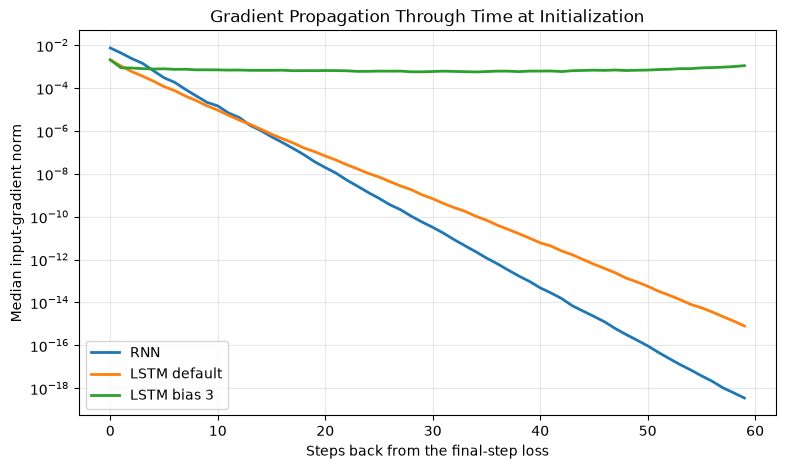

In [39]:
# Plot the curves
fig, ax = plt.subplots(figsize=(9, 5))

for name, curve in gradient_curves.items():
    ax.semilogy(np.arange(60), np.ma.masked_less_equal(curve, 0), label = name, linewidth = 2)

ax.set_xlabel('Steps back from the final-step loss')
ax.set_ylabel('Median input-gradient norm')
ax.set_title('Gradient Propagation Through Time at Initialization')
ax.grid(True, which = 'both', alpha = 0.3)
ax.legend()

fig.savefig(FIGURES_DIR / 'gradient_through_time.png', dpi = 200, bbox_inches = 'tight')

plt.show()

In [ ]:
# Generate gradient summary with four required distances
gradient_summary = gradient_medians_df.loc[[0, 9, 29, 59]]

gradient_summary.to_csv(RESULTS_DIR / 'gradient_summary.csv')
gradient_summary.style.format('{:.3e}')

,RNN,LSTM default,LSTM bias 3
steps_back,,,
0,7.434e-03,2.077e-03,2.070e-03
9,2.165e-05,1.490e-05,7.127e-04
29,5.675e-11,1.055e-09,5.765e-04
59,3.493e-19,7.996e-16,1.115e-03


- At **59** steps back, the median input-gradient norm was **3.493e-19** for the RNN, **7.996e-16** for the default LSTM, and **1.115e-03** for the LSTM with forget-gate bias-3.
- The RNN and default LSTM showed strong gradient decay, consistent with their near-chance benchmark accuracy at lengths **30** and **60**. The bias-3 LSTM preserved a substantially stronger long-range gradient, consistent with its successful recall across all lengths.
- Gates provide a memory path, while initialization influences whether that path initially preserves useful gradients. These measurements describe input sensitivity at initialization rather than gradient behavior throughout training.

## 4. Controlled Fixes

Two experiments use sequence length **30** and seeds **0**, **1**, and **2**:

1. An LSTM forget-gate bias sweep using explicit biases **0**, **1**, **2**, and **3**.
2. A plain RNN comparison with gradient clipping enabled and disabled.

All other settings remain at the starter's defaults.

In [40]:
# Compare four explicit forget-gate biases
bias_rows = []

for gate_bias in [0.0, 1.0, 2.0, 3.0]:
    for seed in SEEDS:
        print(f'LSTM: bias = {gate_bias}, seed = {seed}', flush = True)

        accuracy, _ = train_recall('lstm', seq_len = 30, seed = seed, gate_bias = gate_bias)

        bias_rows.append({
            'forget_bias': gate_bias,
            'seed': seed,
            'accuracy': accuracy,
            })

        # Preserve completed runs
        pd.DataFrame(bias_rows).to_csv(RESULTS_DIR / 'bias_sweep_runs.csv', index = False)

        print(f'Accuracy: {accuracy:.3f}')

bias_df = pd.DataFrame(bias_rows)

LSTM: bias = 0.0, seed = 0
Accuracy: 0.247
LSTM: bias = 0.0, seed = 1
Accuracy: 0.251
LSTM: bias = 0.0, seed = 2
Accuracy: 0.258
LSTM: bias = 1.0, seed = 0
Accuracy: 0.495
LSTM: bias = 1.0, seed = 1
Accuracy: 0.496
LSTM: bias = 1.0, seed = 2
Accuracy: 1.000
LSTM: bias = 2.0, seed = 0
Accuracy: 1.000
LSTM: bias = 2.0, seed = 1
Accuracy: 1.000
LSTM: bias = 2.0, seed = 2
Accuracy: 1.000
LSTM: bias = 3.0, seed = 0
Accuracy: 1.000
LSTM: bias = 3.0, seed = 1
Accuracy: 1.000
LSTM: bias = 3.0, seed = 2
Accuracy: 1.000


In [41]:
# Create summary DataFrame
bias_table = bias_df.pivot(index = 'forget_bias', columns = 'seed', values = 'accuracy').reindex(index = [0.0, 1.0, 2.0, 3.0], columns = SEEDS)
bias_table.columns = [f'seed_{seed}' for seed in SEEDS]
bias_table['mean'] = bias_table.mean(axis=1)

bias_table.to_csv(RESULTS_DIR / 'bias_sweep_summary.csv')

bias_table.style.format('{:.3f}')

,seed_0,seed_1,seed_2,mean
forget_bias,,,,
0.000000,0.247,0.251,0.258,0.252
1.000000,0.495,0.496,1.000,0.664
2.000000,1.000,1.000,1.000,1.000
3.000000,1.000,1.000,1.000,1.000


In [42]:
# Compare the plain RNN with and without parameter-gradient clipping
clipping_rows = []

for condition, clip in [('On (1.0)', 1.0), ('Off', None)]:
    for seed in SEEDS:
        print(f'RNN: clipping = {condition}, seed = {seed}', flush = True)

        accuracy, _ = train_recall('rnn', seq_len = 30, seed = seed, clip = clip)
        clipping_rows.append({
            'clipping': condition,
            'seed': seed,
            'accuracy': accuracy,
            })

        pd.DataFrame(clipping_rows).to_csv(RESULTS_DIR / 'clipping_runs.csv', index = False,)
        print(f'Accuracy: {accuracy:.3f}')

clipping_df = pd.DataFrame(clipping_rows)

RNN: clipping = On (1.0), seed = 0
Accuracy: 0.248
RNN: clipping = On (1.0), seed = 1
Accuracy: 0.251
RNN: clipping = On (1.0), seed = 2
Accuracy: 0.264
RNN: clipping = Off, seed = 0
Accuracy: 0.248
RNN: clipping = Off, seed = 1
Accuracy: 0.251
RNN: clipping = Off, seed = 2
Accuracy: 0.264


In [43]:
# Summarize clipping results
clipping_table = clipping_df.pivot(index = 'clipping', columns = 'seed', values = 'accuracy',).reindex(index = ['On (1.0)', 'Off'], columns = SEEDS)
clipping_table.columns = [f'seed_{seed}' for seed in SEEDS]
clipping_table['mean'] = clipping_table.mean(axis = 1)

clipping_table.to_csv(RESULTS_DIR / 'clipping_summary.csv')

clipping_table.style.format('{:.3f}')

,seed_0,seed_1,seed_2,mean
clipping,,,,
On (1.0),0.248,0.251,0.264,0.254
Off,0.248,0.251,0.264,0.254


- The explicit forget-bias-0 LSTM remained near chance accuracy. Bias 1 produced seed-dependent outcomes: **0.495**, **0.496**, and **1.000**. Biases 2 and 3 achieved **1.000** for every seed.
- The sweep supports the importance of initialization for learning longer dependencies within the fixed training budget.
- Clipping on and off produced identical displayed accuracies for every seed, with a mean of **0.254**. This agrees with the prediction that clipping alone would not solve the 30-step RNN task.
- The RNN's measured gradient decay provides a consistent explanation: clipping limits large parameter gradients but cannot restore vanished long-range gradients. Clipping activation during training was not measured.